In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
orders = pd.read_csv(
    "orders.csv",
    parse_dates=["order_date"]
)

order_items = pd.read_csv("order_items.csv")

products = pd.read_csv("products.csv")

customers = pd.read_csv("customers.csv")

In [3]:
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)

Orders: (9245, 7)
Order Items: (15608, 5)
Products: (90, 5)
Customers: (3600, 4)


In [4]:
orders.head()

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
0,100001,1530,01-01-2024 09:24,completed,credit_card,NaN,6.95
1,100002,3531,01-01-2024 10:37,completed,credit_card,NaN,0.00
2,100003,840,01-01-2024 10:59,completed,credit_card,NaN,0.00
3,100004,725,01-01-2024 12:48,completed,apple_pay,WELCOME10,0.00
4,100005,3452,01-01-2024 17:44,completed,gift_card,NaN,0.00


In [5]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9245 entries, 0 to 9244
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        9245 non-null   int64  
 1   customer_id     9245 non-null   int64  
 2   order_date      9245 non-null   object 
 3   status          9245 non-null   object 
 4   payment_method  9245 non-null   object 
 5   discount_code   1411 non-null   object 
 6   shipping_fee    9245 non-null   float64
dtypes: float64(1), int64(2), object(4)
memory usage: 505.7+ KB


In [6]:
# 1. Check date data type
print(orders["order_date"].dtype)

object


In [7]:
# 2. Check missing values in all columns
print(orders.isnull().sum())

order_id             0
customer_id          0
order_date           0
status               0
payment_method       0
discount_code     7834
shipping_fee         0
dtype: int64


In [8]:
# 3. Inspect status labels and discount code values
print(orders["status"].value_counts(dropna=False))
print(orders["discount_code"].value_counts(dropna=False).head(10))

status
completed    8490
returned      409
canceled      346
Name: count, dtype: int64
discount_code
NaN          7834
HOLIDAY20     782
WELCOME10     391
SPRING15      238
Name: count, dtype: int64


In [9]:
# Preserve original values for validation
original_dates = orders["order_date"].copy()

# Convert to datetime
orders["order_date"] = pd.to_datetime(
    orders["order_date"],
    errors="coerce"
)

print("Data type:", orders["order_date"].dtype)
print("Invalid dates:", orders["order_date"].isna().sum())

Data type: datetime64[ns]
Invalid dates: 5686


In [10]:
invalid_dates = orders.loc[
    orders["order_date"].isna(),
    ["order_id"]
].copy()

invalid_dates["original_date"] = original_dates.loc[
    orders["order_date"].isna()
]

invalid_dates.head(20)

,order_id,original_date
116,100117,13-01-2024 06:39
117,100118,13-01-2024 09:36
118,100119,13-01-2024 10:27
119,100120,13-01-2024 18:14
120,100121,13-01-2024 18:34
121,100122,13-01-2024 21:36
122,100123,14-01-2024 06:15
123,100124,14-01-2024 10:12
124,100125,14-01-2024 11:11
125,100126,14-01-2024 14:11


In [11]:
orders["order_date"] = pd.to_datetime(
    original_dates,
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Data type:", orders["order_date"].dtype)
print("Invalid dates:", orders["order_date"].isna().sum())

Data type: datetime64[ns]
Invalid dates: 0


In [12]:
orders[["order_id", "order_date"]].head(10)

,order_id,order_date
0,100001,2024-01-01 09:24:00
1,100002,2024-01-01 10:37:00
2,100003,2024-01-01 10:59:00
3,100004,2024-01-01 12:48:00
4,100005,2024-01-01 17:44:00
5,100006,2024-01-01 19:10:00
6,100007,2024-01-01 23:25:00
7,100008,2024-01-02 06:08:00
8,100009,2024-01-02 10:16:00
9,100010,2024-01-02 15:18:00


In [13]:
orders.loc[
    orders["order_date"].isna(),
    ["order_id"]
].head()

,order_id


In [14]:
print(
    "Duplicate order IDs:",
    orders["order_id"].duplicated().sum()
)

print(
    "Exact duplicate rows:",
    orders.duplicated().sum()
)

Duplicate order IDs: 38
Exact duplicate rows: 38


In [15]:
duplicate_orders = orders[
    orders["order_id"].duplicated(keep=False)
].sort_values("order_id")

duplicate_orders

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
47,100048,3320,2024-01-06 16:37:00,completed,credit_card,NaN,6.95
8560,100048,3320,2024-01-06 16:37:00,completed,credit_card,NaN,6.95
7556,100303,853,2024-02-03 08:33:00,completed,apple_pay,NaN,0.00
303,100303,853,2024-02-03 08:33:00,completed,apple_pay,NaN,0.00
5488,100710,526,2024-03-13 13:39:00,completed,credit_card,NaN,0.00
...,...,...,...,...,...,...,...
8617,108585,1995,2025-11-28 12:43:00,completed,apple_pay,HOLIDAY20,0.00
9104,109068,1981,2025-12-20 13:27:00,completed,credit_card,HOLIDAY20,6.95
3104,109068,1981,2025-12-20 13:27:00,completed,credit_card,HOLIDAY20,6.95
4213,109087,3358,2025-12-22 08:35:00,completed,credit_card,HOLIDAY20,0.00


In [16]:
duplicate_orders.groupby("order_id").nunique()

,customer_id,order_date,status,payment_method,discount_code,shipping_fee
order_id,,,,,,
100048,1,1,1,1,0,1
100303,1,1,1,1,0,1
100710,1,1,1,1,0,1
100779,1,1,1,1,0,1
101380,1,1,1,1,0,1
101813,1,1,1,1,0,1
102000,1,1,1,1,0,1
102064,1,1,1,1,0,1
102345,1,1,1,1,0,1


In [17]:
orders_clean = orders.drop_duplicates().copy()

print("Original rows:", len(orders))
print("Cleaned rows:", len(orders_clean))
print(
    "Duplicate order IDs remaining:",
    orders_clean["order_id"].duplicated().sum()
)

Original rows: 9245
Cleaned rows: 9207
Duplicate order IDs remaining: 0


Duplicate order records: The orders dataset contained 38 exact duplicate rows. Since the dataset is defined as one row per order, one copy of each duplicated record was retained. The original dataset was preserved for traceability.

In [ ]:
print(products["category"].value_counts(dropna=False))

category
Kitchen       10
Outdoor        9
Furniture      9
Bath           9
Lighting       8
Bedding        8
Decor          8
Storage        7
decor          4
 Bedding       2
 Kitchen       2
Storage        2
bedding        1
KITCHEN        1
Kitchen        1
kitchen        1
FURNITURE      1
furniture      1
Furniture      1
bath           1
BEDDING        1
 Outdoor       1
LIGHTING       1
OUTDOOR        1
Name: count, dtype: int64


In [21]:
print(
    products["category"]
    .dropna()
    .unique()
)

['Kitchen' ' Kitchen' 'Kitchen ' 'kitchen' 'KITCHEN' ' Bedding' 'Bedding'
 'bedding' 'BEDDING' 'Bath' 'bath' 'Furniture' 'Furniture ' 'furniture'
 'FURNITURE' 'Lighting' 'LIGHTING' 'Outdoor' 'OUTDOOR' ' Outdoor' 'Decor'
 'decor' 'Storage' 'Storage ']


In [22]:
products_clean = products.copy()

products_clean["category"] = (
    products_clean["category"]
    .str.strip()
    .str.title()
)

In [23]:
print(products_clean["category"].value_counts())
print("Unique categories:", products_clean["category"].nunique())

category
Kitchen      15
Bedding      12
Furniture    12
Decor        12
Outdoor      11
Bath         10
Lighting      9
Storage       9
Name: count, dtype: int64
Unique categories: 8


Category standardization: Product category labels contained inconsistent capitalization and leading/trailing whitespace. Whitespace was removed and capitalization was standardized to title case. The original category column was preserved in the source DataFrame.

In [24]:
items_with_date = order_items.merge(
    orders_clean[["order_id", "order_date"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

missing_prices = items_with_date[
    items_with_date["unit_price"].isna()
]

missing_prices[
    ["order_id", "product_id", "order_date", "quantity"]
].head(10)

,order_id,product_id,order_date,quantity
55,100033,1086,2024-01-05 10:24:00,1
110,100062,1020,2024-01-07 13:33:00,1
197,100116,1087,2024-01-12 23:20:00,2
366,100210,1014,2024-01-24 11:11:00,1
626,100361,1077,2024-02-08 15:58:00,1
685,100396,1015,2024-02-12 07:12:00,1
822,100468,1004,2024-02-18 17:21:00,2
958,100545,1090,2024-02-26 10:33:00,2
1007,100573,1090,2024-02-28 21:06:00,1
1125,100639,1087,2024-03-05 18:11:00,2


In [25]:
# Historical prices available for each product
known_prices = items_with_date[
    items_with_date["unit_price"].notna()
]

historical_summary = (
    known_prices.groupby("product_id")["unit_price"]
    .agg(["count", "min", "max", "nunique"])
)

historical_summary.head(10)

,count,min,max,nunique
product_id,,,,
1001,219,61.99,65.09,2
1002,201,138.99,145.94,2
1003,212,22.99,24.14,2
1004,191,75.99,79.79,2
1005,207,79.99,83.99,2
1006,226,16.99,17.84,2
1007,211,71.99,75.59,2
1008,215,43.99,46.19,2
1009,221,131.99,138.59,2


In [27]:
missing_product_ids = missing_prices["product_id"].unique()

historical_summary.loc[
    historical_summary.index.isin(missing_product_ids)
].sort_values("nunique", ascending=False)

,count,min,max,nunique
product_id,,,,
1001,219,61.99,65.09,2
1002,201,138.99,145.94,2
1003,212,22.99,24.14,2
1004,191,75.99,79.79,2
1005,207,79.99,83.99,2
...,...,...,...,...
1086,205,97.99,102.89,2
1087,226,45.99,48.29,2
1088,192,20.99,22.04,2


In [28]:
known_prices = (
    items_with_date.loc[
        items_with_date["unit_price"].notna(),
        ["product_id", "order_date", "unit_price"]
    ]
    .rename(columns={
        "order_date": "reference_date",
        "unit_price": "historical_unit_price"
    })
    .sort_values("reference_date")
)

candidates = pd.merge_asof(
    missing_prices.sort_values("order_date"),
    known_prices,
    left_on="order_date",
    right_on="reference_date",
    by="product_id",
    direction="nearest"
)

In [29]:
candidates["date_gap_days"] = (
    candidates["order_date"] -
    candidates["reference_date"]
).abs().dt.total_seconds() / 86400

candidates[
    [
        "order_id",
        "product_id",
        "order_date",
        "reference_date",
        "historical_unit_price",
        "date_gap_days"
    ]
].head(15)

,order_id,product_id,order_date,reference_date,historical_unit_price,date_gap_days
0,100033,1086,2024-01-05 10:24:00,2024-01-05 09:51:00,97.99,0.022917
1,100062,1020,2024-01-07 13:33:00,2024-01-10 22:58:00,54.99,3.392361
2,100116,1087,2024-01-12 23:20:00,2024-01-12 20:43:00,45.99,0.109028
3,100210,1014,2024-01-24 11:11:00,2024-01-23 18:15:00,36.99,0.705556
4,100361,1077,2024-02-08 15:58:00,2024-02-11 09:48:00,25.99,2.743056
5,100396,1015,2024-02-12 07:12:00,2024-02-13 17:38:00,96.99,1.434722
6,100468,1004,2024-02-18 17:21:00,2024-02-24 08:15:00,75.99,5.620833
7,100545,1090,2024-02-26 10:33:00,2024-02-26 21:48:00,17.99,0.468750
8,100573,1090,2024-02-28 21:06:00,2024-02-27 09:37:00,17.99,1.478472
9,100639,1087,2024-03-05 18:11:00,2024-03-06 06:19:00,45.99,0.505556


In [30]:
candidates["date_gap_days"].describe()

count    199.000000
mean       2.068223
std        2.481226
min        0.002083
25%        0.460069
50%        1.359722
75%        2.354167
max       15.096528
Name: date_gap_days, dtype: float64

In [31]:
print(
    "Within 7 days:",
    (candidates["date_gap_days"] <= 7).sum()
)

print(
    "More than 7 days:",
    (candidates["date_gap_days"] > 7).sum()
)

Within 7 days: 188
More than 7 days: 11


In [32]:
candidates_previous = pd.merge_asof(
    missing_prices.sort_values("order_date"),
    known_prices.sort_values("reference_date"),
    left_on="order_date",
    right_on="reference_date",
    by="product_id",
    direction="backward"
)

In [33]:
candidates_previous = pd.merge_asof(
    missing_prices.sort_values("order_date"),
    known_prices.sort_values("reference_date"),
    left_on="order_date",
    right_on="reference_date",
    by="product_id",
    direction="backward"
)

candidates_previous["date_gap_days"] = (
    candidates_previous["order_date"]
    - candidates_previous["reference_date"]
).dt.total_seconds() / 86400

print(
    "No previous price found:",
    candidates_previous["reference_date"].isna().sum()
)

print(
    "Within 7 days:",
    (candidates_previous["date_gap_days"] <= 7).sum()
)

print(
    "More than 7 days:",
    (candidates_previous["date_gap_days"] > 7).sum()
)

No previous price found: 1
Within 7 days: 162
More than 7 days: 36


In [34]:
candidates_previous["imputation_eligible"] = (
    candidates_previous["reference_date"].notna()
    & (candidates_previous["date_gap_days"] <= 7)
)

print(
    candidates_previous["imputation_eligible"].value_counts()
)

imputation_eligible
True     162
False     37
Name: count, dtype: int64


In [35]:
candidates_previous.loc[
    candidates_previous["imputation_eligible"],
    [
        "order_id",
        "product_id",
        "order_date",
        "reference_date",
        "historical_unit_price",
        "date_gap_days"
    ]
].head(10)

,order_id,product_id,order_date,reference_date,historical_unit_price,date_gap_days
0,100033,1086,2024-01-05 10:24:00,2024-01-05 09:51:00,97.99,0.022917
2,100116,1087,2024-01-12 23:20:00,2024-01-12 20:43:00,45.99,0.109028
3,100210,1014,2024-01-24 11:11:00,2024-01-23 18:15:00,36.99,0.705556
4,100361,1077,2024-02-08 15:58:00,2024-02-03 12:49:00,25.99,5.131250
5,100396,1015,2024-02-12 07:12:00,2024-02-09 14:10:00,96.99,2.709722
7,100545,1090,2024-02-26 10:33:00,2024-02-25 08:07:00,17.99,1.101389
8,100573,1090,2024-02-28 21:06:00,2024-02-27 09:37:00,17.99,1.478472
9,100639,1087,2024-03-05 18:11:00,2024-03-03 10:42:00,45.99,2.311806
10,100664,1037,2024-03-08 11:25:00,2024-03-08 07:54:00,28.99,0.146528
11,100834,1041,2024-03-25 17:37:00,2024-03-22 13:58:00,553.99,3.152083


In [36]:
items_clean = items_with_date.copy()

# Keep track of which prices were originally missing
items_clean["price_was_missing"] = (
    items_clean["unit_price"].isna()
)

In [37]:
price_lookup = candidates_previous[
    [
        "order_id",
        "product_id",
        "historical_unit_price",
        "date_gap_days",
        "imputation_eligible"
    ]
].copy()

items_clean = items_clean.merge(
    price_lookup,
    on=["order_id", "product_id"],
    how="left",
    validate="many_to_one"
)

In [39]:
eligible = (
    items_clean["price_was_missing"]
    & items_clean["imputation_eligible"].fillna(False)
)

items_clean.loc[eligible, "unit_price"] = (
    items_clean.loc[eligible, "historical_unit_price"]
)

C:\Users\MAYURESH GAIKWAD\AppData\Local\Temp\ipykernel_30840\192088112.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  & items_clean["imputation_eligible"].fillna(False)


In [40]:
print("Original missing prices:",
      items_clean["price_was_missing"].sum())

print("Prices imputed:",
      (eligible).sum())

print("Prices still missing:",
      items_clean["unit_price"].isna().sum())

Original missing prices: 199
Prices imputed: 162
Prices still missing: 37


In [41]:
print(products_clean["category"].value_counts())

print(
    "Total unique categories:",
    products_clean["category"].nunique()
)

category
Kitchen      15
Bedding      12
Furniture    12
Decor        12
Outdoor      11
Bath         10
Lighting      9
Storage       9
Name: count, dtype: int64
Total unique categories: 8


In [42]:
items_clean["net_line_sales"] = (
    items_clean["quantity"] * items_clean["unit_price"]
    - items_clean["discount_amount"]
)

In [43]:
print(
    "Rows with missing prices:",
    items_clean["unit_price"].isna().sum()
)

print(
    "Rows with missing line sales:",
    items_clean["net_line_sales"].isna().sum()
)

Rows with missing prices: 37
Rows with missing line sales: 37


In [44]:
sales_data = items_clean.merge(
    orders_clean[
        ["order_id", "order_date", "status", "shipping_fee"]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

In [45]:
completed_sales = sales_data[
    sales_data["status"] == "completed"
].copy()

print("Completed order-item rows:", len(completed_sales))

print(
    "Completed sales with missing prices:",
    completed_sales["unit_price"].isna().sum()
)

Completed order-item rows: 14283
Completed sales with missing prices: 33


In [46]:
print(
    "Missing-price rows:",
    completed_sales["unit_price"].isna().sum()
)

print(
    "Units affected:",
    completed_sales.loc[
        completed_sales["unit_price"].isna(),
        "quantity"
    ].sum()
)

Missing-price rows: 33
Units affected: 40


In [47]:
known_sales = completed_sales[
    completed_sales["unit_price"].notna()
]

unknown_sales = completed_sales[
    completed_sales["unit_price"].isna()
]

print(
    "Known net product sales:",
    known_sales["net_line_sales"].sum()
)

print(
    "Rows with unknown net sales:",
    len(unknown_sales)
)

Known net product sales: 1876682.2799999998
Rows with unknown net sales: 33


In [48]:
price_coverage = (
    completed_sales["unit_price"].notna().mean() * 100
)

print(f"Price coverage: {price_coverage:.2f}%")

Price coverage: 99.77%


In [51]:
print(completed_sales.columns.tolist())

['order_id', 'product_id', 'quantity', 'unit_price', 'discount_amount', 'order_date_x', 'price_was_missing', 'historical_unit_price', 'date_gap_days', 'imputation_eligible', 'net_line_sales', 'order_date_y', 'status', 'shipping_fee']


In [52]:
monthly_revenue = (
    completed_sales
    .groupby(
        completed_sales["order_date_x"].dt.to_period("M")
    )["net_line_sales"]
    .sum(min_count=1)
)

monthly_revenue

order_date_x
2024-01     54334.52
2024-02     63122.64
2024-03     71531.80
2024-04     64747.75
2024-05     73145.85
2024-06     67108.39
2024-07     76739.07
2024-08     62625.59
2024-09     60054.02
2024-10     67129.85
2024-11    100382.26
2024-12     86517.00
2025-01     72895.31
2025-02     70306.83
2025-03     78616.92
2025-04     79926.95
2025-05     82817.63
2025-06     92022.44
2025-07     83255.06
2025-08     91547.36
2025-09     75215.77
2025-10     81938.59
2025-11    129661.14
2025-12     91039.54
Freq: M, Name: net_line_sales, dtype: float64

In [53]:
monthly_df = monthly_revenue.rename("revenue").reset_index()

monthly_df["year"] = monthly_df["order_date_x"].dt.year
monthly_df["month"] = monthly_df["order_date_x"].dt.month

comparison = monthly_df.pivot(
    index="month",
    columns="year",
    values="revenue"
)

comparison["YoY Growth %"] = (
    (comparison[2025] - comparison[2024])
    / comparison[2024]
) * 100

comparison.round(2)

year,2024,2025,YoY Growth %
month,,,
1,54334.52,72895.31,34.16
2,63122.64,70306.83,11.38
3,71531.80,78616.92,9.90
4,64747.75,79926.95,23.44
5,73145.85,82817.63,13.22
6,67108.39,92022.44,37.13
7,76739.07,83255.06,8.49
8,62625.59,91547.36,46.18
9,60054.02,75215.77,25.25


In [54]:
annual_revenue = monthly_df.groupby("year")["revenue"].sum()

print("Annual Revenue:")
print(annual_revenue.round(2))

growth_pct = (
    (annual_revenue.loc[2025] - annual_revenue.loc[2024])
    / annual_revenue.loc[2024]
) * 100

print(f"\nAnnual Revenue Growth: {growth_pct:.2f}%")

Annual Revenue:
year
2024     847438.74
2025    1029243.54
Name: revenue, dtype: float64

Annual Revenue Growth: 21.45%


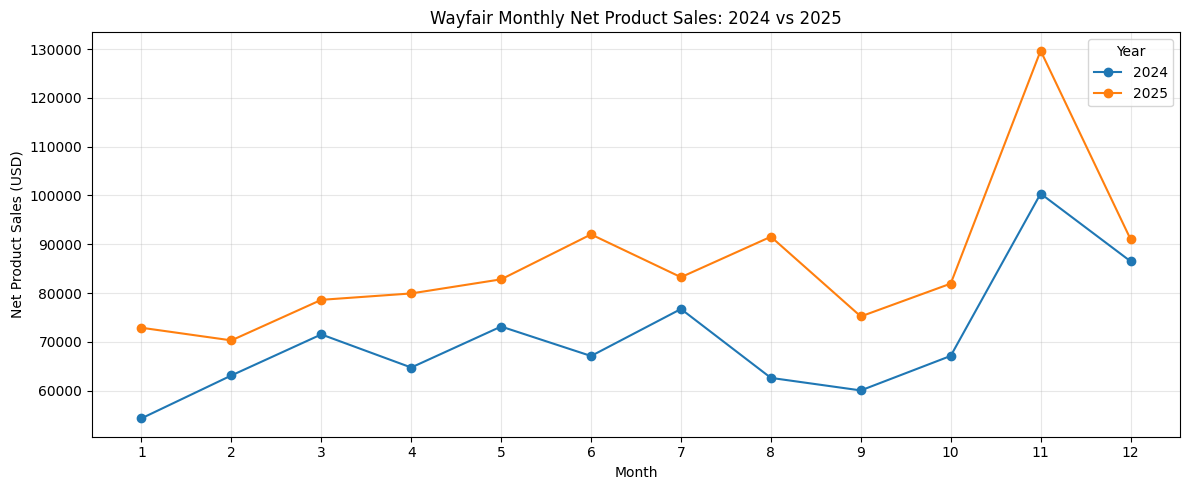

In [ ]:
plt.figure(figsize=(12, 5))

for year in [2024, 2025]:
    year_data = monthly_df[monthly_df["year"] == year]

    plt.plot(
        year_data["month"],
        year_data["revenue"],
        marker="o",
        label=str(year)
    )

plt.title("Wayfair Monthly Net Product Sales: 2024 vs 2025")
plt.xlabel("Month")
plt.ylabel("Net Product Sales (USD)")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

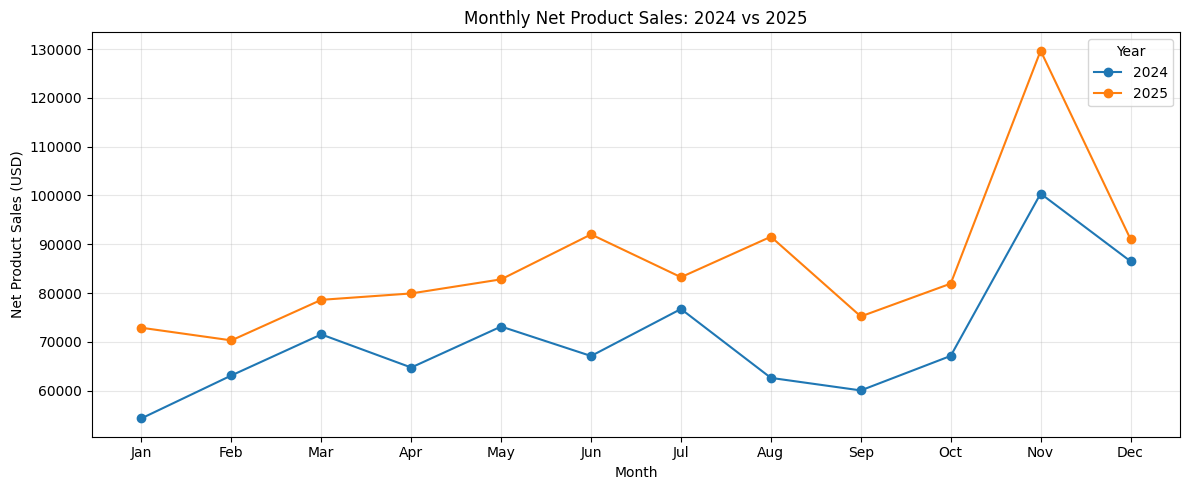

In [56]:
import calendar

plt.figure(figsize=(12, 5))

for year in [2024, 2025]:
    year_data = monthly_df[monthly_df["year"] == year]

    plt.plot(
        year_data["month"],
        year_data["revenue"],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Net Product Sales: 2024 vs 2025")
plt.xlabel("Month")
plt.ylabel("Net Product Sales (USD)")
plt.xticks(
    range(1, 13),
    [calendar.month_abbr[m] for m in range(1, 13)]
)
plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [57]:
category_sales = completed_sales.merge(
    products_clean[["product_id", "product_name", "category"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

category_revenue = (
    category_sales
    .groupby("category")["net_line_sales"]
    .sum()
    .sort_values(ascending=False)
)

category_revenue

category
Furniture    320305.87
Kitchen      279258.87
Decor        277680.43
Bedding      266698.36
Outdoor      246902.87
Lighting     237400.26
Storage      139469.01
Bath         108966.61
Name: net_line_sales, dtype: float64

In [58]:
category_summary = category_revenue.reset_index()
category_summary.columns = ["category", "revenue"]

category_summary["revenue_share_pct"] = (
    category_summary["revenue"]
    / category_summary["revenue"].sum()
) * 100

category_summary

,category,revenue,revenue_share_pct
0,Furniture,320305.87,17.067666
1,Kitchen,279258.87,14.880455
2,Decor,277680.43,14.796347
3,Bedding,266698.36,14.211162
4,Outdoor,246902.87,13.156349
5,Lighting,237400.26,12.649997
6,Storage,139469.01,7.431679
7,Bath,108966.61,5.806343


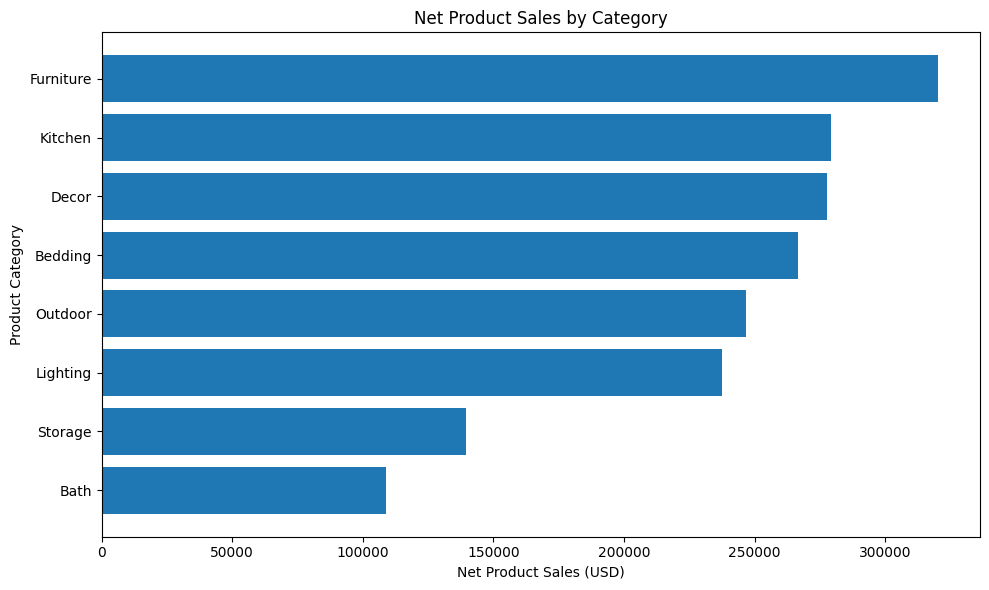

In [59]:
category_summary = category_summary.sort_values(
    "revenue", ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    category_summary["category"],
    category_summary["revenue"]
)

plt.title("Net Product Sales by Category")
plt.xlabel("Net Product Sales (USD)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [60]:
top_products = (
    category_sales
    .groupby(["product_id", "product_name", "category"])["net_line_sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

product_id  product_name               category 
1059        Cotton Patio Chair         Outdoor      67034.90
1042        Classic Dining Chair Pair  Furniture    51243.95
1072        Coastal Picture Frame Set  Decor        44000.98
1018        Ceramic Quilt              Bedding      41400.47
1044        Bamboo Nightstand          Furniture    41365.73
1076        Modern Wreath              Decor        41022.95
1041        Nordic Side Table          Furniture    40394.19
1054        Velvet String Lights       Lighting     38838.42
1080        Classic Garland            Decor        38681.43
1040        Marble Bookshelf           Furniture    38595.66
Name: net_line_sales, dtype: float64

In [61]:
category_summary = category_revenue.reset_index()
category_summary.columns = ["category", "revenue"]

category_summary["revenue_share_pct"] = (
    category_summary["revenue"]
    / category_summary["revenue"].sum()
) * 100

category_summary.sort_values(
    "revenue", ascending=False
).round(2)

,category,revenue,revenue_share_pct
0,Furniture,320305.87,17.07
1,Kitchen,279258.87,14.88
2,Decor,277680.43,14.80
3,Bedding,266698.36,14.21
4,Outdoor,246902.87,13.16
5,Lighting,237400.26,12.65
6,Storage,139469.01,7.43
7,Bath,108966.61,5.81


In [62]:
order_categories = (
    order_items[["order_id", "product_id"]]
    .drop_duplicates()
    .merge(
        products_clean[["product_id", "category"]],
        on="product_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        orders_clean[["order_id", "status"]],
        on="order_id",
        how="left",
        validate="many_to_one"
    )
)

In [63]:
category_orders = (
    order_categories
    .groupby("category")
    .agg(
        total_orders=("order_id", "nunique"),
        returned_orders=(
            "status",
            lambda s: order_categories.loc[
                s.index, "order_id"
            ][s == "returned"].nunique()
        ),
        canceled_orders=(
            "status",
            lambda s: order_categories.loc[
                s.index, "order_id"
            ][s == "canceled"].nunique()
        )
    )
)

category_orders["return_rate_pct"] = (
    category_orders["returned_orders"]
    / category_orders["total_orders"] * 100
)

category_orders["cancellation_rate_pct"] = (
    category_orders["canceled_orders"]
    / category_orders["total_orders"] * 100
)

category_orders.sort_values(
    "return_rate_pct", ascending=False
).round(2)

,total_orders,returned_orders,canceled_orders,return_rate_pct,cancellation_rate_pct
category,,,,,
Furniture,1007,118,31,11.72,3.08
Bedding,1800,91,59,5.06,3.28
Bath,1643,73,75,4.44,4.56
Outdoor,1353,60,50,4.43,3.70
Decor,2729,114,95,4.18,3.48
Storage,1733,72,58,4.15,3.35
Kitchen,2844,118,108,4.15,3.80
Lighting,1227,49,36,3.99,2.93


In [64]:
category_orders.sort_values(
    "return_rate_pct",
    ascending=False
).round(2)

,total_orders,returned_orders,canceled_orders,return_rate_pct,cancellation_rate_pct
category,,,,,
Furniture,1007,118,31,11.72,3.08
Bedding,1800,91,59,5.06,3.28
Bath,1643,73,75,4.44,4.56
Outdoor,1353,60,50,4.43,3.70
Decor,2729,114,95,4.18,3.48
Storage,1733,72,58,4.15,3.35
Kitchen,2844,118,108,4.15,3.80
Lighting,1227,49,36,3.99,2.93


In [65]:
category_aov = (
    category_sales
    .groupby("category")
    .agg(
        category_revenue=("net_line_sales", "sum"),
        completed_orders=("order_id", "nunique")
    )
)

category_aov["category_aov"] = (
    category_aov["category_revenue"]
    / category_aov["completed_orders"]
)

category_aov.sort_values(
    "category_aov",
    ascending=False
).round(2)

,category_revenue,completed_orders,category_aov
category,,,
Furniture,320305.87,858,373.32
Lighting,237400.26,1142,207.88
Outdoor,246902.87,1243,198.63
Bedding,266698.36,1650,161.64
Decor,277680.43,2520,110.19
Kitchen,279258.87,2618,106.67
Storage,139469.01,1603,87.00
Bath,108966.61,1495,72.89


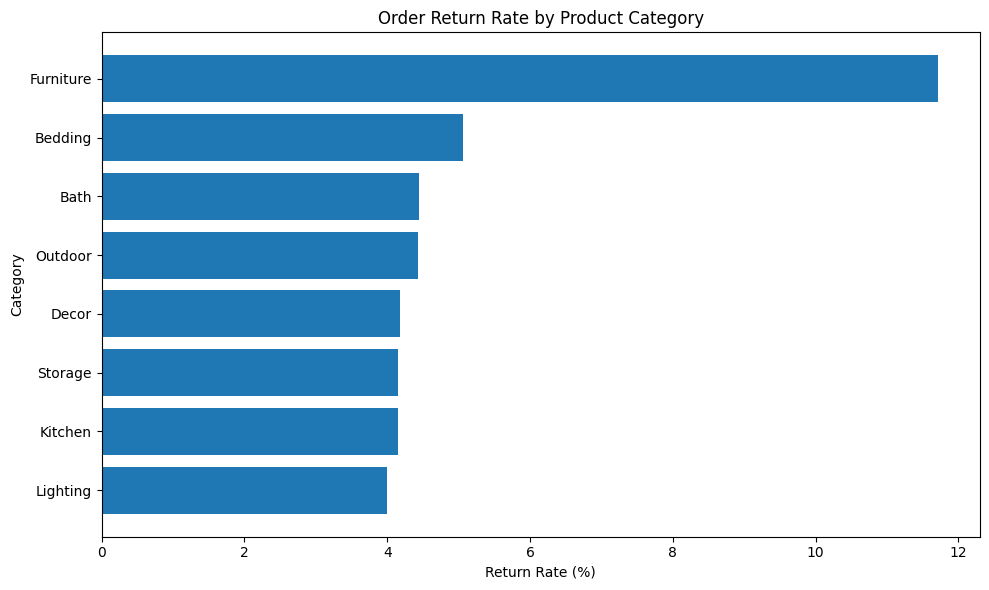

In [66]:
return_chart = category_orders.sort_values(
    "return_rate_pct",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    return_chart.index,
    return_chart["return_rate_pct"]
)

plt.title("Order Return Rate by Product Category")
plt.xlabel("Return Rate (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [67]:
category_sales["month"] = (
    category_sales["order_date_x"].dt.to_period("M")
)

monthly_category_revenue = (
    category_sales
    .groupby(["month", "category"])["net_line_sales"]
    .sum()
    .reset_index()
)

monthly_category_revenue.head(10)

,month,category,net_line_sales
0,2024-01,Bath,3954.39
1,2024-01,Bedding,10777.03
2,2024-01,Decor,8205.65
3,2024-01,Furniture,6623.77
4,2024-01,Kitchen,8872.35
5,2024-01,Lighting,9052.85
6,2024-01,Outdoor,1674.89
7,2024-01,Storage,5173.59
8,2024-02,Bath,4133.90
9,2024-02,Bedding,9993.80


In [68]:
monthly_category_revenue["monthly_total"] = (
    monthly_category_revenue
    .groupby("month")["net_line_sales"]
    .transform("sum")
)

monthly_category_revenue["revenue_share_pct"] = (
    monthly_category_revenue["net_line_sales"]
    / monthly_category_revenue["monthly_total"]
) * 100

monthly_category_revenue.head(10)

,month,category,net_line_sales,monthly_total,revenue_share_pct
0,2024-01,Bath,3954.39,54334.52,7.277859
1,2024-01,Bedding,10777.03,54334.52,19.834591
2,2024-01,Decor,8205.65,54334.52,15.102093
3,2024-01,Furniture,6623.77,54334.52,12.190721
4,2024-01,Kitchen,8872.35,54334.52,16.329122
5,2024-01,Lighting,9052.85,54334.52,16.661323
6,2024-01,Outdoor,1674.89,54334.52,3.082552
7,2024-01,Storage,5173.59,54334.52,9.521737
8,2024-02,Bath,4133.90,63122.64,6.548997
9,2024-02,Bedding,9993.80,63122.64,15.832354


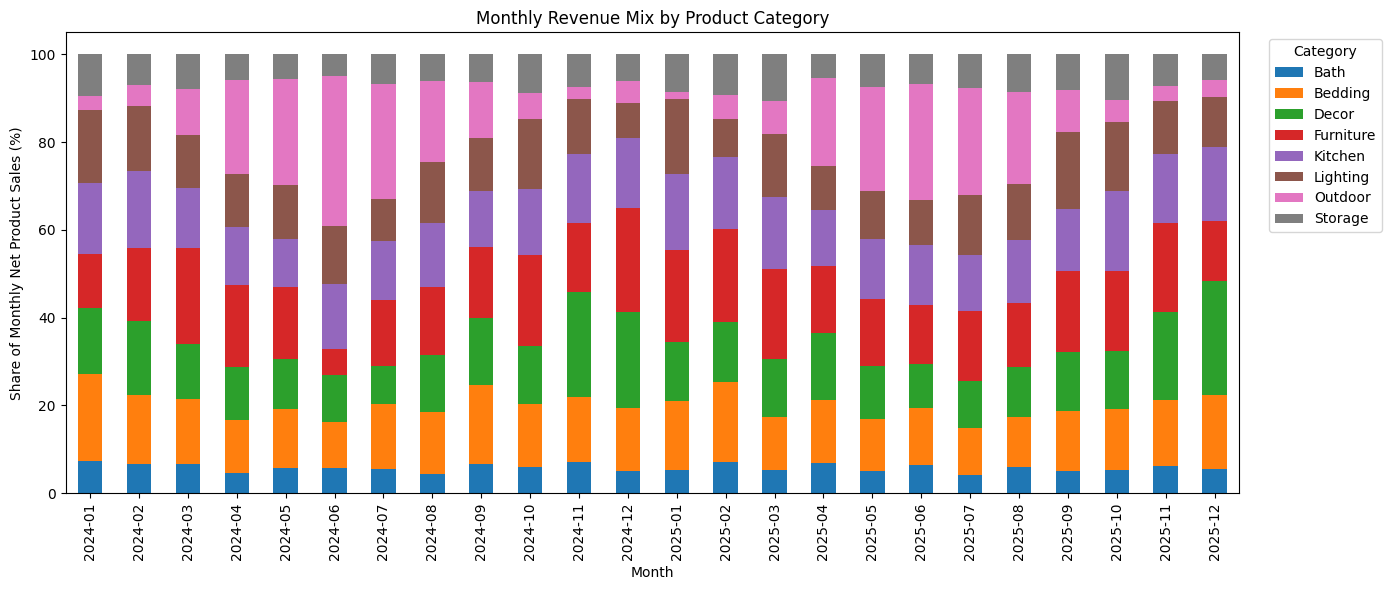

In [69]:
category_pivot = monthly_category_revenue.pivot(
    index="month",
    columns="category",
    values="revenue_share_pct"
)

category_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6)
)

plt.title("Monthly Revenue Mix by Product Category")
plt.xlabel("Month")
plt.ylabel("Share of Monthly Net Product Sales (%)")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [70]:
mix = monthly_category_revenue.copy()

mix["year"] = mix["month"].dt.year
mix["month_num"] = mix["month"].dt.month

share_comparison = mix.pivot(
    index=["month_num", "category"],
    columns="year",
    values="revenue_share_pct"
)

share_comparison["change_pp"] = (
    share_comparison[2025] - share_comparison[2024]
)

share_comparison["abs_change"] = (
    share_comparison["change_pp"].abs()
)

share_comparison.sort_values(
    "abs_change", ascending=False
).head(10).round(2)

year                  2024   2025  change_pp  abs_change
month_num category                                      
12        Furniture  23.74  13.86      -9.88        9.88
1         Furniture  12.19  20.88       8.69        8.69
6         Outdoor    34.30  26.36      -7.94        7.94
          Furniture   5.88  13.58       7.70        7.70
2         Lighting   14.74   8.67      -6.07        6.07
9         Lighting   12.00  17.67       5.67        5.67
11        Furniture  15.53  20.33       4.80        4.80
2         Furniture  16.70  21.25       4.56        4.56
7         Lighting    9.49  13.76       4.27        4.27
1         Bedding    19.83  15.65      -4.18        4.18

In [71]:
december_furniture = monthly_category_revenue[
    (monthly_category_revenue["month"].dt.month == 12)
    & (monthly_category_revenue["category"] == "Furniture")
].copy()

december_furniture[
    ["month", "net_line_sales", "monthly_total", "revenue_share_pct"]
]

,month,net_line_sales,monthly_total,revenue_share_pct
91,2024-12,20539.09,86517.00,23.739947
187,2025-12,12613.63,91039.54,13.855112


In [72]:
dec_furniture_products = category_sales[
    (category_sales["category"] == "Furniture")
    & (category_sales["order_date_x"].dt.month == 12)
].copy()

dec_furniture_products["year"] = (
    dec_furniture_products["order_date_x"].dt.year
)

product_comparison = dec_furniture_products.pivot_table(
    index=["product_id", "product_name"],
    columns="year",
    values="net_line_sales",
    aggfunc="sum",
    fill_value=0
)

product_comparison["change_usd"] = (
    product_comparison[2025] - product_comparison[2024]
)

product_comparison.sort_values(
    "change_usd"
).head(10).round(2)

,year,2024,2025,change_usd
product_id,product_name,,,
1042,Classic Dining Chair Pair,6811.11,2275.53,-4535.58
1041,Nordic Side Table,3545.53,0.00,-3545.53
1045,Rattan Console Table,2027.96,1064.68,-963.28
1038,Linen Accent Chair,816.37,0.00,-816.37
1039,Nordic Coffee Table,1451.97,914.74,-537.23
1043,Stoneware Bar Stool,409.56,241.90,-167.66
1046,Nordic Storage Bench,571.96,450.42,-121.54
1048,Linen Loveseat,531.96,411.57,-120.39
1049,Linen TV Stand,457.16,520.03,62.87


In [73]:
dec_furniture_products["year"] = (
    dec_furniture_products["order_date_x"].dt.year
)

product_demand = dec_furniture_products.pivot_table(
    index=["product_id", "product_name"],
    columns="year",
    values=["order_id", "quantity"],
    aggfunc={
        "order_id": "nunique",
        "quantity": "sum"
    },
    fill_value=0
)

product_demand

order_id      quantity     
year                                     2024 2025     2024 2025
product_id product_name                                         
1038       Linen Accent Chair               3    0        3    0
1039       Nordic Coffee Table              3    2        3    2
1040       Marble Bookshelf                 8    8        8    8
1041       Nordic Side Table                7    0        7    0
1042       Classic Dining Chair Pair        9    3        9    3
1043       Stoneware Bar Stool              4    2        4    2
1044       Bamboo Nightstand                0    5        0    5
1045       Rattan Console Table             4    2        4    2
1046       Nordic Storage Bench             4    3        4    3
1047       Modern Writing Desk              1    2        1    2
1048       Linen Loveseat                   4    3        4    3
1049       Linen TV Stand                   4    4        4    4

In [74]:
dec_furniture_products["discount_rate"] = (
    dec_furniture_products["discount_amount"]
    / (
        dec_furniture_products["quantity"]
        * dec_furniture_products["unit_price"]
    )
).where(
    dec_furniture_products["quantity"]
    * dec_furniture_products["unit_price"] > 0
)

discount_comparison = dec_furniture_products.pivot_table(
    index=["product_id", "product_name"],
    columns="year",
    values="discount_rate",
    aggfunc="mean"
)

discount_comparison.round(3)

,year,2024,2025
product_id,product_name,,
1038,Linen Accent Chair,0.133,NaN
1039,Nordic Coffee Table,0.000,0.100
1040,Marble Bookshelf,0.025,0.050
1041,Nordic Side Table,0.086,NaN
1042,Classic Dining Chair Pair,0.022,0.067
1043,Stoneware Bar Stool,0.200,0.100
1044,Bamboo Nightstand,NaN,0.080
1045,Rattan Console Table,0.000,0.000
1046,Nordic Storage Bench,0.000,0.000


In [75]:
furniture_monthly = (
    category_sales[
        category_sales["category"] == "Furniture"
    ]
    .assign(
        year=lambda df: df["order_date_x"].dt.year,
        month_num=lambda df: df["order_date_x"].dt.month
    )
    .pivot_table(
        index="month_num",
        columns="year",
        values="net_line_sales",
        aggfunc="sum"
    )
)

furniture_monthly["change_pct"] = (
    (furniture_monthly[2025] - furniture_monthly[2024])
    / furniture_monthly[2024]
) * 100

furniture_monthly.round(2)

year,2024,2025,change_pct
month_num,,,
1,6623.77,15218.95,129.76
2,10540.29,14942.81,41.77
3,15726.34,16154.11,2.72
4,12135.58,12162.22,0.22
5,12018.51,12703.93,5.70
6,3947.86,12497.81,216.57
7,11626.26,13421.79,15.44
8,9676.72,13358.49,38.05
9,9747.72,13887.98,42.47


In [76]:
annual_revenue = monthly_revenue.groupby(
    monthly_revenue.index.year
).sum()

print(annual_revenue.round(2))

annual_growth = (
    (annual_revenue.loc[2025] - annual_revenue.loc[2024])
    / annual_revenue.loc[2024]
) * 100

print(f"Annual growth: {annual_growth:.2f}%")

order_date_x
2024     847438.74
2025    1029243.54
Name: net_line_sales, dtype: float64
Annual growth: 21.45%


In [77]:
furniture_orders = (
    order_categories[
        order_categories["category"] == "Furniture"
    ]
    .drop_duplicates(["order_id", "category"])
)

product_returns = (
    order_items[["order_id", "product_id"]]
    .drop_duplicates()
    .merge(
        products_clean[["product_id", "product_name", "category"]],
        on="product_id",
        how="left"
    )
    .merge(
        orders_clean[["order_id", "status"]],
        on="order_id",
        how="left"
    )
)

product_returns = product_returns[
    product_returns["category"] == "Furniture"
]

return_summary = (
    product_returns
    .groupby(["product_id", "product_name"])
    .agg(
        total_orders=("order_id", "nunique"),
        returned_orders=(
            "status",
            lambda s: (s == "returned").sum()
        )
    )
)

return_summary["return_rate_pct"] = (
    return_summary["returned_orders"]
    / return_summary["total_orders"] * 100
)

return_summary.sort_values(
    "return_rate_pct", ascending=False
).round(2).head(10)

,,total_orders,returned_orders,return_rate_pct
product_id,product_name,,,
1043,Stoneware Bar Stool,81,16,19.75
1048,Linen Loveseat,100,14,14.00
1046,Nordic Storage Bench,89,12,13.48
1047,Modern Writing Desk,97,13,13.40
1049,Linen TV Stand,93,12,12.90
1038,Linen Accent Chair,81,10,12.35
1041,Nordic Side Table,85,10,11.76
1040,Marble Bookshelf,94,9,9.57
1042,Classic Dining Chair Pair,79,7,8.86
